In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

(4080, 3060, 3)


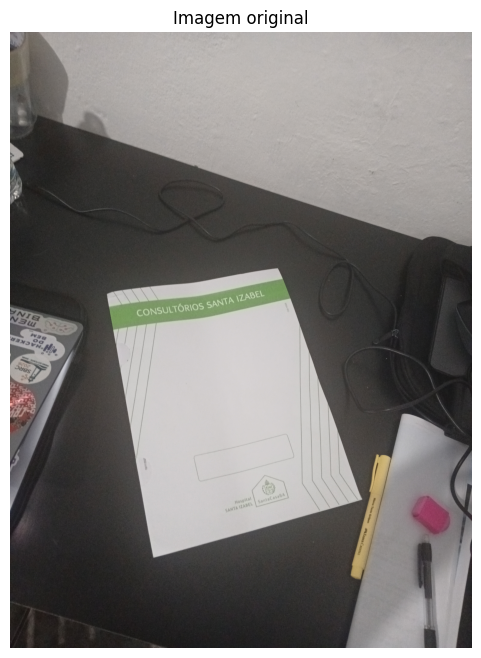

In [ ]:
img = cv2.imread("imgHomografia.jpg")
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(img.shape)

plt.figure(figsize=(6, 8))
plt.imshow(rgb); plt.title("Imagem original"); plt.axis("off")
plt.show()

In [ ]:
S = img.shape[1] / 1500.0
print("Resolução:", img.shape, "| S =", round(S, 4))

pts_src = (np.array([[315, 818], [868, 768], [1140, 1543], [462, 1700]],
                    dtype=np.float32) * S).round(1)
print("Pontos origem (u, v):\n", pts_src)

Resolução: (4080, 3060, 3) | S = 2.04
Pontos origem (u, v):
 [[ 642.6 1668.7]
 [1770.7 1566.7]
 [2325.6 3147.7]
 [ 942.5 3468. ]]


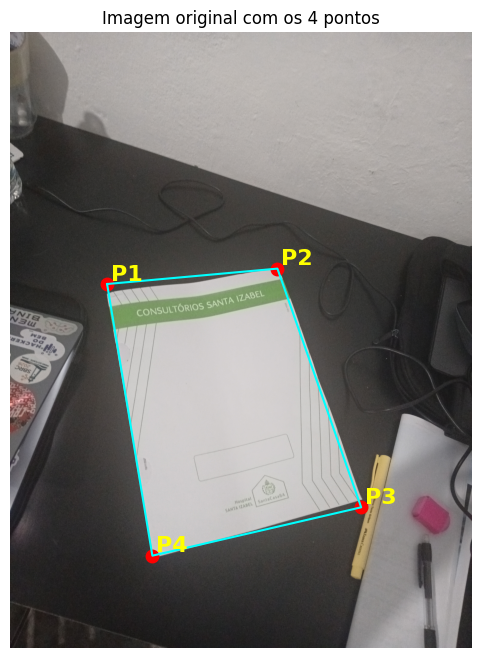

In [ ]:
labels = ["P1", "P2", "P3", "P4"]
fig, ax = plt.subplots(figsize=(6, 8))
ax.imshow(rgb)
for (u, v), l in zip(pts_src, labels):
    ax.plot(u, v, "o", color="red", ms=9)
    ax.text(u + 25, v - 25, l, color="yellow", fontsize=16, weight="bold")
ax.plot(*np.vstack([pts_src, pts_src[0]]).T, "-", color="cyan", lw=1.5)
ax.set_title("Imagem original com os 4 pontos"); ax.axis("off")
fig.savefig("fig_pontos.png", dpi=130, bbox_inches="tight")
plt.show()

In [ ]:
W, H = 840, 1188
pts_dst = np.array([[0, 0], [W, 0], [W, H], [0, H]], dtype=np.float32)
print("Pontos destino (x, y):\n", pts_dst)

Pontos destino (x, y):
 [[   0.    0.]
 [ 840.    0.]
 [ 840. 1188.]
 [   0. 1188.]]


In [ ]:
Hm = cv2.getPerspectiveTransform(pts_src, pts_dst)
Hm = Hm / Hm[2, 2]
print("H =\n", Hm)

H =
 [[    0.885591    -0.147607  -322.769275]
 [    0.09973      1.10299  -1904.646137]
 [   -0.00008      0.000222     1.      ]]


In [ ]:
ret = cv2.warpPerspective(img, Hm, (W, H), flags=cv2.INTER_LINEAR)
cv2.imwrite("imagem_retificada.png", ret)
ret_rgb = cv2.cvtColor(ret, cv2.COLOR_BGR2RGB)

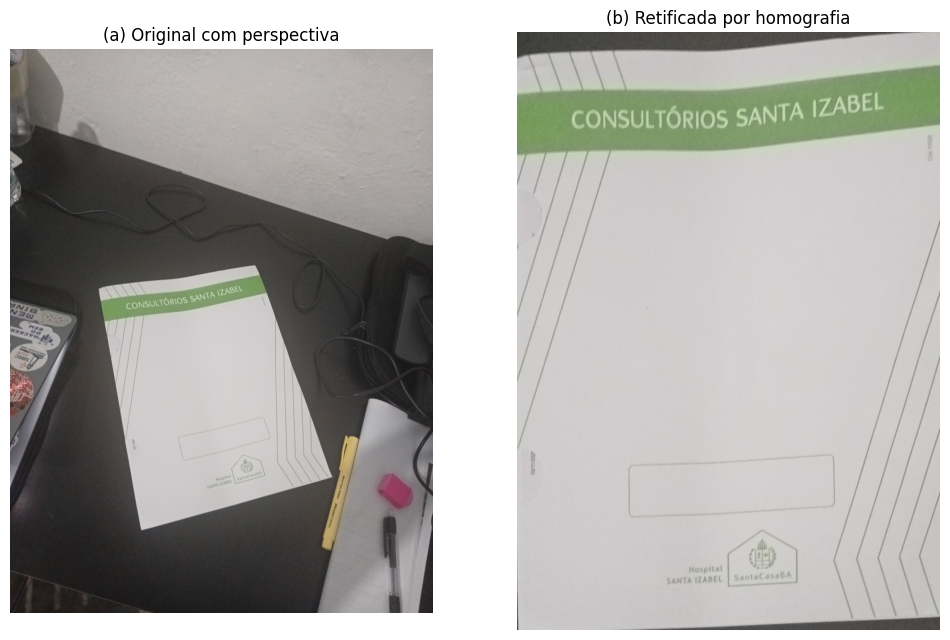

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 8))
axs[0].imshow(rgb);     axs[0].set_title("(a) Original com perspectiva"); axs[0].axis("off")
axs[1].imshow(ret_rgb); axs[1].set_title("(b) Retificada por homografia"); axs[1].axis("off")
fig.savefig("fig_comparacao.png", dpi=130, bbox_inches="tight")
plt.show()

Pt  = (1546.3, 2851.9)
P~' (antes de normalizar) = [ 625.674774 1395.207922    1.510742]
P't = (414.2, 923.5)


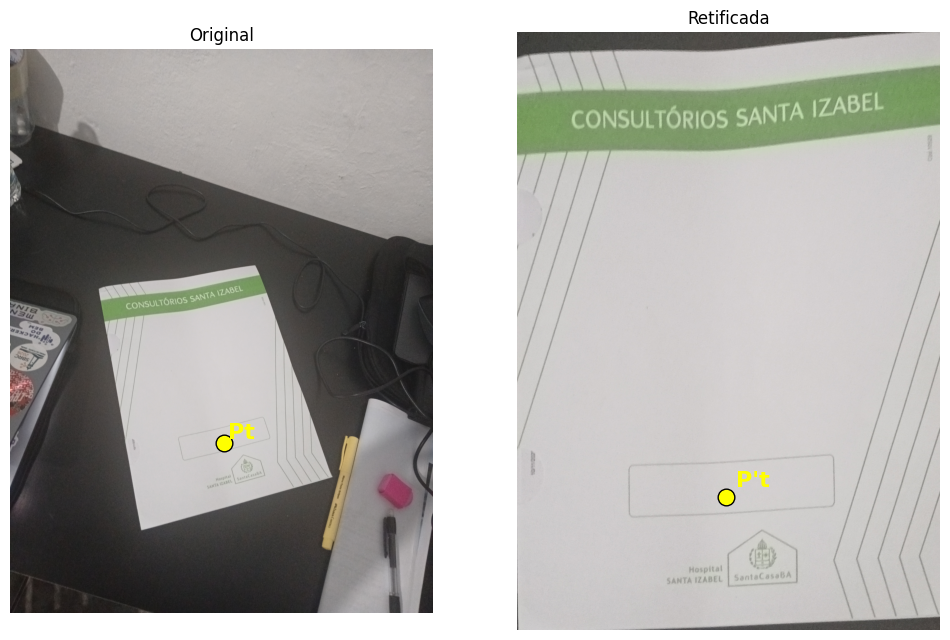

In [ ]:
Pt = np.array([758 * S, 1398 * S, 1.0])
Pp = Hm @ Pt
xt, yt = Pp[0] / Pp[2], Pp[1] / Pp[2]

print(f"Pt  = ({Pt[0]:.1f}, {Pt[1]:.1f})")
print("P~' (antes de normalizar) =", Pp)
print(f"P't = ({xt:.1f}, {yt:.1f})")

fig, axs = plt.subplots(1, 2, figsize=(12, 8))
axs[0].imshow(rgb)
axs[0].plot(Pt[0], Pt[1], "o", color="yellow", mec="k", ms=12)
axs[0].text(Pt[0] + 30, Pt[1] - 30, "Pt", color="yellow", fontsize=16, weight="bold")
axs[0].set_title("Original"); axs[0].axis("off")
axs[1].imshow(ret_rgb)
axs[1].plot(xt, yt, "o", color="yellow", mec="k", ms=12)
axs[1].text(xt + 20, yt - 20, "P't", color="yellow", fontsize=16, weight="bold")
axs[1].set_title("Retificada"); axs[1].axis("off")
fig.savefig("fig_ponto_teste.png", dpi=130, bbox_inches="tight")
plt.show()